# Experiment 7: Logical and Probabilistic Reasoning

**Aim:** To implement basic Propositional Logic, First-Order Logic, and probability-based reasoning using Python.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Propositional Logic

Rule: **If it rains, then the road is wet.**

\[
Rain \rightarrow Wet
\]

In [2]:
print("PROPOSITIONAL LOGIC")
print("Rule: If it rains, then the road is wet.\n")
print("Rain\tWet\tRain -> Wet")

for rain in [False, True]:
    for wet in [False, True]:
        result = (not rain) or wet
        print(f"{rain}\t{wet}\t{result}")

PROPOSITIONAL LOGIC
Rule: If it rains, then the road is wet.

Rain	Wet	Rain -> Wet
False	False	True
False	True	True
True	False	False
True	True	True


In [3]:
rain = np.array([False, False, True, True])
wet = np.array([False, True, False, True])
implication = (~rain) | wet

truth_table = pd.DataFrame({
    "Rain (P)": rain,
    "Wet (Q)": wet,
    "P -> Q": implication
})
print(truth_table)

   Rain (P)  Wet (Q)  P -> Q
0     False    False    True
1     False     True    True
2      True    False   False
3      True     True    True


## 2. First-Order Logic

Statements:
- All humans are mortal.
- Socrates is a human.
- Therefore, Socrates is mortal.

In [4]:
human = {
    "Socrates": True,
    "Plato": True,
    "Aristotle": True
}

def mortal(person):
    return human.get(person, False)

person = "Socrates"

if human.get(person, False):
    print(person, "is a human.")
    print("Therefore,", person, "is mortal.")
else:
    print(person, "is not known to be human.")

Socrates is a human.
Therefore, Socrates is mortal.


## 3. Probability of Events

Let:
- **A = Student passed**
- **B = Student attended**

In [5]:
data = pd.DataFrame({
    "Student": ["S1","S2","S3","S4","S5","S6","S7","S8","S9","S10"],
    "Passed": [1,1,0,1,0,1,0,1,0,1],
    "Attended": [1,1,1,0,1,1,0,0,1,1]
})

print(data)

  Student  Passed  Attended
0      S1       1         1
1      S2       1         1
2      S3       0         1
3      S4       1         0
4      S5       0         1
5      S6       1         1
6      S7       0         0
7      S8       1         0
8      S9       0         1
9     S10       1         1


In [6]:
total = len(data)

P_A = data["Passed"].sum() / total
P_B = data["Attended"].sum() / total

both = ((data["Passed"] == 1) & (data["Attended"] == 1)).sum()
P_A_and_B = both / total

P_A_or_B = P_A + P_B - P_A_and_B

print("P(A) =", P_A)
print("P(B) =", P_B)
print("P(A ∩ B) =", P_A_and_B)
print("P(A ∪ B) =", P_A_or_B)

P(A) = 0.6
P(B) = 0.7
P(A ∩ B) = 0.4
P(A ∪ B) = 0.8999999999999998


## 4. Conditional Probability

\[
P(A|B)=\frac{P(A\cap B)}{P(B)}
\]

\[
P(B|A)=\frac{P(A\cap B)}{P(A)}
\]

In [7]:
P_A_given_B = P_A_and_B / P_B
P_B_given_A = P_A_and_B / P_A

print("P(A | B) =", P_A_given_B)
print("P(B | A) =", P_B_given_A)

P(A | B) = 0.5714285714285715
P(B | A) = 0.6666666666666667


In [8]:
probabilities = {
    "P(A)": P_A,
    "P(B)": P_B,
    "P(A ∩ B)": P_A_and_B,
    "P(A ∪ B)": P_A_or_B,
    "P(A | B)": P_A_given_B,
    "P(B | A)": P_B_given_A
}

for name, value in probabilities.items():
    print(f"{name} = {value:.3f}")

P(A) = 0.600
P(B) = 0.700
P(A ∩ B) = 0.400
P(A ∪ B) = 0.900
P(A | B) = 0.571
P(B | A) = 0.667


## 5. Bayes' Theorem

Disease diagnosis example:
- P(Disease) = 1%
- P(Positive | Disease) = 90%
- P(Positive | No Disease) = 5%

In [9]:
P_D = 0.01
P_Pos_given_D = 0.90
P_Pos_given_notD = 0.05

P_notD = 1 - P_D
P_Pos = (P_Pos_given_D * P_D) + (P_Pos_given_notD * P_notD)

P_D_given_Pos = (P_Pos_given_D * P_D) / P_Pos

print("P(Disease) =", P_D)
print("P(Positive | Disease) =", P_Pos_given_D)
print("P(Positive | No Disease) =", P_Pos_given_notD)
print("P(Positive) =", P_Pos)
print("P(Disease | Positive) =", P_D_given_Pos)

P(Disease) = 0.01
P(Positive | Disease) = 0.9
P(Positive | No Disease) = 0.05
P(Positive) = 0.0585
P(Disease | Positive) = 0.15384615384615385


## 6. Visualization

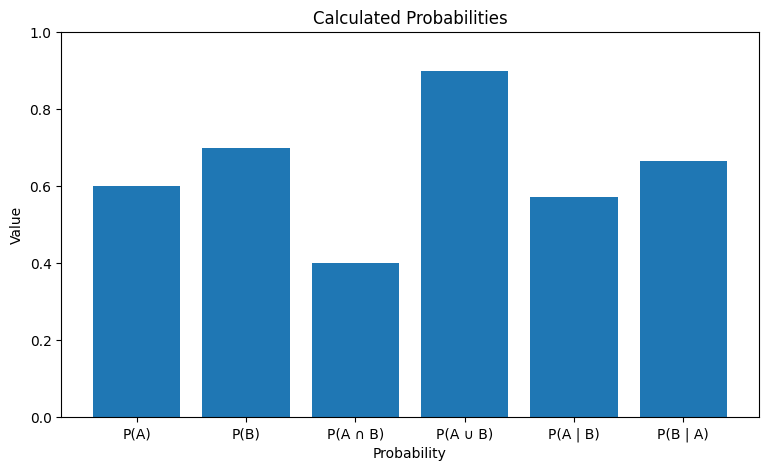

In [10]:
names = list(probabilities.keys())
values = list(probabilities.values())

plt.figure(figsize=(9, 5))
plt.bar(names, values)
plt.xlabel("Probability")
plt.ylabel("Value")
plt.title("Calculated Probabilities")
plt.ylim(0, 1)
plt.show()

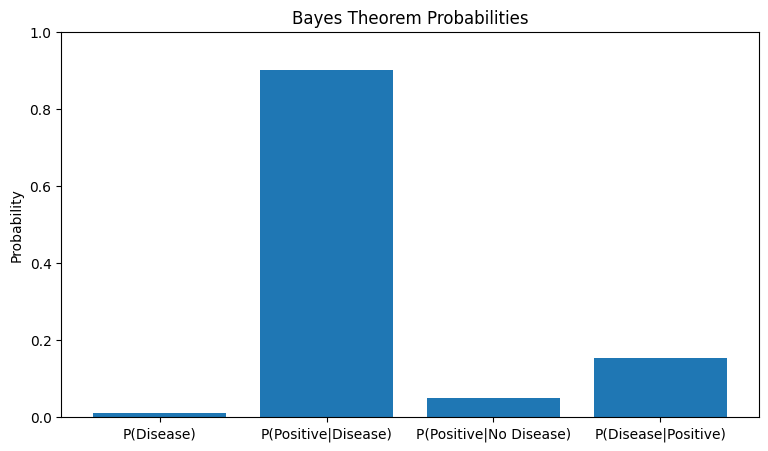

In [11]:
labels = [
    "P(Disease)",
    "P(Positive|Disease)",
    "P(Positive|No Disease)",
    "P(Disease|Positive)"
]

values = [
    P_D,
    P_Pos_given_D,
    P_Pos_given_notD,
    P_D_given_Pos
]

plt.figure(figsize=(9, 5))
plt.bar(labels, values)
plt.ylabel("Probability")
plt.title("Bayes Theorem Probabilities")
plt.ylim(0, 1)
plt.show()

### Modify an Input Probability

Change the false-positive probability from **5% to 10%** and observe the change.

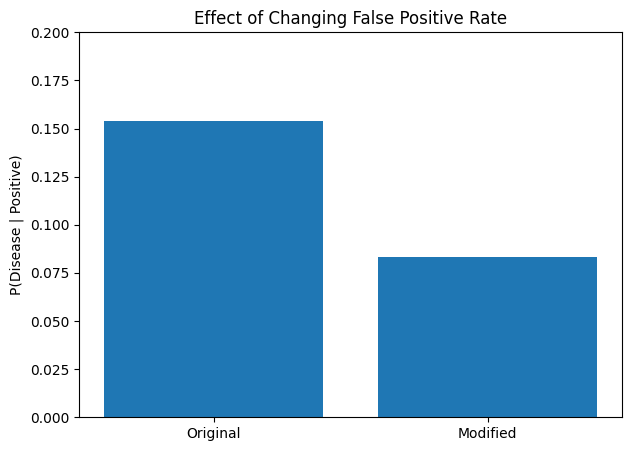

Original: 0.1538
Modified: 0.0833


In [12]:
original = P_D_given_Pos

P_Pos_given_notD = 0.10
P_Pos = (P_Pos_given_D * P_D) + (P_Pos_given_notD * P_notD)
modified = (P_Pos_given_D * P_D) / P_Pos

plt.figure(figsize=(7, 5))
plt.bar(["Original", "Modified"], [original, modified])
plt.ylabel("P(Disease | Positive)")
plt.title("Effect of Changing False Positive Rate")
plt.ylim(0, 0.2)
plt.show()

print("Original:", round(original, 4))
print("Modified:", round(modified, 4))

In [13]:
print("=" * 50)
print("EXPERIMENT 7 SUMMARY")
print("=" * 50)
print("Propositional Logic: Truth table generated.")
print("First-Order Logic: Socrates is mortal.")
print("P(A) =", round(P_A, 3))
print("P(B) =", round(P_B, 3))
print("P(A ∩ B) =", round(P_A_and_B, 3))
print("P(A ∪ B) =", round(P_A_or_B, 3))
print("P(A | B) =", round(P_A_given_B, 3))
print("P(B | A) =", round(P_B_given_A, 3))
print("P(Disease | Positive) =", round(original, 3))
print("Visualization completed.")

EXPERIMENT 7 SUMMARY
Propositional Logic: Truth table generated.
First-Order Logic: Socrates is mortal.
P(A) = 0.6
P(B) = 0.7
P(A ∩ B) = 0.4
P(A ∪ B) = 0.9
P(A | B) = 0.571
P(B | A) = 0.667
P(Disease | Positive) = 0.154
Visualization completed.
